##### Recherche du minimum

##### Graphiques

In [1]:
from algo.neldermead import NelderMead, init_simplex
from utils.point import Point

def f(p: Point)->float:
    result = 0

    for x in p:
        result += x**4

    return result

n_itr = 10000
epsilon = 0.015742814751489097

best_values = []
history_step = []

times = []
avg_times = []

for i in range(10):
    simplex = init_simplex([1 for i in range(10)], 0.5)
    algo = NelderMead(
        simplex,
        f,
        scalaire_reflexion=1,
        scalaire_expansion=2,
        scalaire_contraction=0.5,
        scalaire_homothetie=0.5
    )
    algo.compute(n_itr)

    best_point = algo.history_benchmark["best_points"][-1]
    best_value = algo.history_benchmark["best_values"][-1]

    best_values = [v for v in algo.history_benchmark["best_values"] if v > epsilon]

    history_step = [v for v in algo.history if v["step"] < len(best_values) ]

    if i == 0:
        print("Meilleur point:", best_point)
        print("Valeur du meilleur point:", best_value)
        print("Itération avant convergence:", len(best_values))

    __times = algo.history_benchmark["execution_time"]
    _times = [__times[i] for i in range(len(best_values))]
    times.append(sum(_times))
    avg_times.append(sum(_times) / len(_times))

print('--------')
print("Temps d'exécution:", sum(times) / len(times), "ns")
print("Temps d'exécution moyens par itr: ", sum(avg_times) / len(avg_times), "ns")
print("Meilleur point (ε):", algo.history_benchmark["best_points"][len(best_values) - 1])
print("Valeur meilleur point (ε):", best_values[-1])

Meilleur point: Point([2.9514834660144715e-20, -8.61856897985801e-20, 3.755826280775102e-20, -5.2927706647700566e-20, 1.7821201427718404e-20, -5.7291351754496e-20, -9.713612392225457e-20, 1.9504996432092114e-20, 5.008887315360384e-20, -2.0125399538408583e-20], Dimension: 10)
Valeur du meilleur point: 1.722759917315641e-76
Itération avant convergence: 141
--------
Temps d'exécution: 7119270.0 ns
Temps d'exécution moyens par itr:  50491.276595744675 ns
Meilleur point (ε): Point([-0.17717393741678422, 0.2119253872952691, 0.1657094516558485, 0.23379521219079002, 0.2722567579249591, -0.2438820632187121, 0.0916171402372487, 0.016425369966917375, 0.035173373411066744, -0.24790698463155003], Dimension: 10)
Valeur meilleur point (ε): 0.019625403634745547


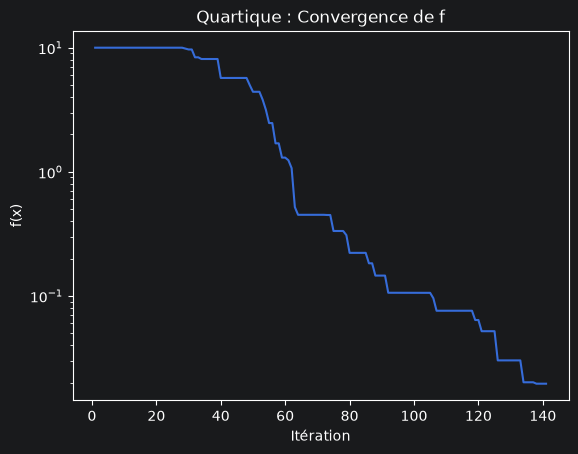

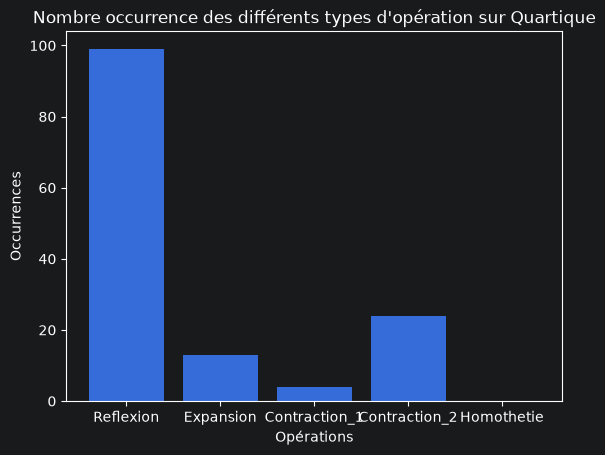

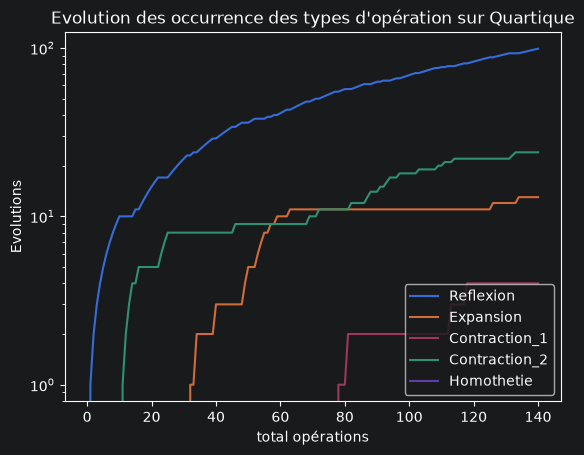

In [2]:
from benchmark.benchmark_utils import *

graph_convergence(best_values, "Quartique")
graph_nelder_mead_type_operation(history_step, "Quartique")
graph_nelder_mead_type_2(history_step, "Quartique")